In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def execute_and_plot(circuit, shots):
    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)


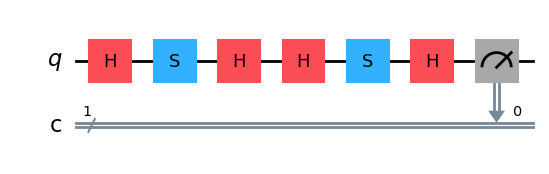

In [4]:
circuit = QuantumCircuit(1,1)

circuit.h(0)
circuit.s(0)
circuit.h(0)

circuit.h(0)
circuit.s(0)
circuit.h(0)

circuit.measure(0,0)

circuit.draw(output='mpl')

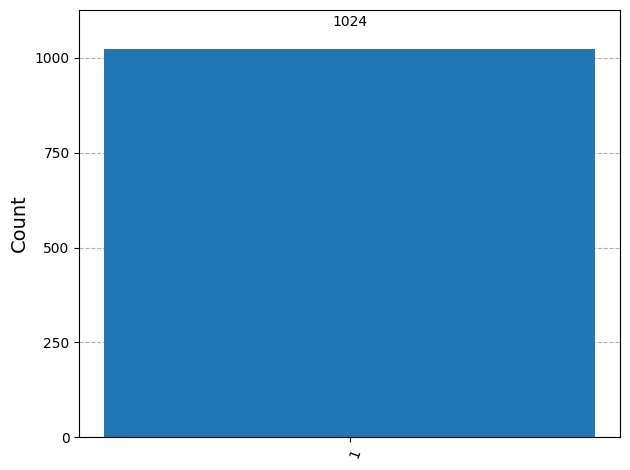

In [5]:
execute_and_plot(circuit=circuit, shots=1024)

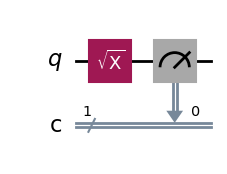

In [8]:
sqrt_not_circuit = QuantumCircuit(1, 1)

# Apply the square root of NOT (SX) gate
sqrt_not_circuit.sx(0)

# Measure the qubit
sqrt_not_circuit.measure(0, 0)

# Draw the circuit
sqrt_not_circuit.draw(output='mpl')

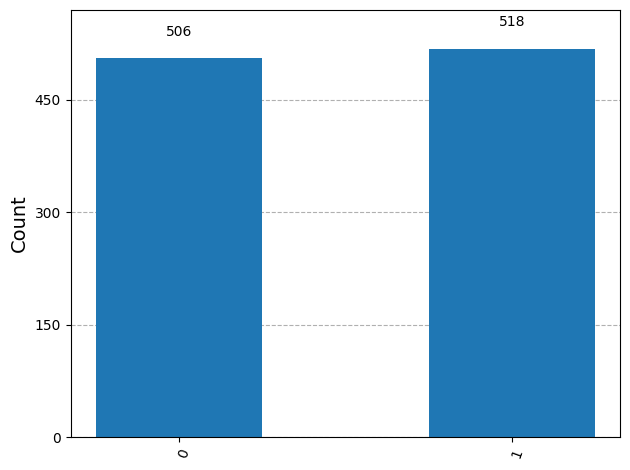

In [9]:
execute_and_plot(circuit=sqrt_not_circuit, shots=1024)

In [10]:
# Print the unitary matrix of the SX (√X) gate
from qiskit.quantum_info import Operator
from qiskit.circuit.library import SXGate

import numpy as np

sx_matrix = Operator(SXGate()).data
np.set_printoptions(precision=3, suppress=True)
print("Unitary matrix of SX (√X) gate:\n", sx_matrix)

Unitary matrix of SX (√X) gate:
 [[0.5+0.5j 0.5-0.5j]
 [0.5-0.5j 0.5+0.5j]]
